# Gradient Boosting Regression

In [29]:
import os
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("future.no_silent_downcasting", True)
warnings.filterwarnings("ignore")
plt.style.use("dark_background")

## Import and Prepare Data

**Select either  `removal` or `recovery` as the desired Output here!**

After selecting the desired output size, the required data is imported. For simplicity's sake, the features (Flow_C, Flow_P, and Current_Limit_P) are always imported from the cache folder here, which saves having to convert them to the correct format from the CSV files. Depending on which output variable you selected previously, either the data for the output variable *Average CO2 Removal* or *Average Water Recovery* is loaded.

In [30]:
output = "removal"

In [31]:
cached_objects_prepared_data_path = os.path.join(
    os.path.dirname(os.getcwd()), "..", "cached_objects", "prepared_data"
)

X = joblib.load(os.path.join(cached_objects_prepared_data_path, "X.npy"))

if output == "removal":
    y = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_removal.npy")
    ).reshape(-1, 1)
    y_label = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_label_removal.npy")
    )
    y_name = "removal"
elif output == "recovery":
    y = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_recovery.npy")
    ).reshape(-1, 1)
    y_label = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_label_recovery.npy")
    )
    y_name = "recovery"

## Gradient Boosting Regression

In contrast to the random forest method for creating models, another method is used here that also employs decision trees, but this time with the function that the trees sequentially correct the errors of the previous tree.

The parameters *n_estimators* and *max_depth* are already familiar from the random forest method. Both should be chosen carefully and preferably a little too small, as both too many decision trees and too great a depth of the individual trees increase the risk of overfitting.
- In GBRT, the *learning_rate* is a particularly important parameter, as it is used to set the proportion of the correction from the previous tree that is adopted. This rate should definitely be less than 1.0 so that the entire correction is not adopted, which would increase the risk of overfitting again.
- Otherwise, it is also important to pay attention to the *min_samples_split* and *subsample* parameters. The minimum number of data points for a split should not be set too low, especially for small data sets. In addition, each decision tree should always have a portion of the data selected at random in order to reduce the risk of overfitting.

In [32]:
model = GradientBoostingRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.1,
    random_state=42
)
model.fit(X, y)

y_pred = model.predict(X)

## Gradient Boosting Regression Key Metrics

In order to better evaluate and compare the model that was created here, we will now discuss a few key metrics.

Feature importance indicates which feature contributed most to improvements in the model. If it is high for a feature, as is the case here for Flow_P, then Flow_P has contributed more to improvements in the decision trees than the feature Current_Limit_P. The differences are even more clearly visible here than in Random Forest Regression. This can be concluded primarily from the fact that the variance in the underlying data set for Current_Limit_P is very low.

In the case of residual distribution, the distribution is ideally symmetrical around 0, which is not the case for average water recovery, as can be seen below. This means that the model can still be used, but the results should be critically questioned. However, the distribution around 0 for the output average CO2 removal is significantly better.

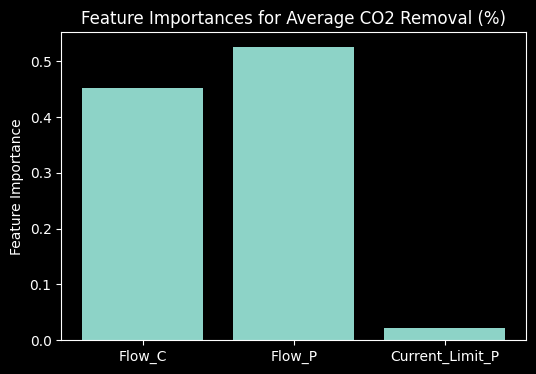

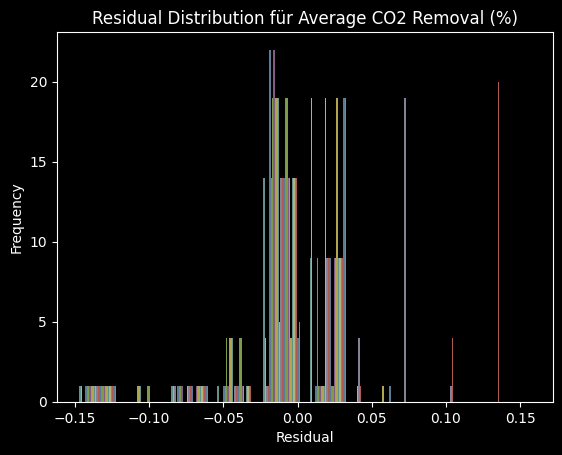

In [33]:
importances = model.feature_importances_
features = ["Flow_C", "Flow_P", "Current_Limit_P"]

# Visualize Feature Importances
plt.figure(figsize=(6, 4))
plt.bar(features, importances)
plt.ylabel("Feature Importance")
plt.title(f"Feature Importances for {y_label}")
plt.show()

# Visualize Residual Distribution
residuals = y - y_pred
plt.hist(residuals, bins=10, alpha=0.7)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title(f"Residual Distribution für {y_label}")
plt.show()

## Validation via LOOCV

Again the *Leave-One-Out Cross-Validation* is used to minimize the amount of data sacrificed as test data. The Mean Squared Error is very low for both Average CO2 Removal and Average Water Recovery.

In [34]:
loo = LeaveOneOut()
y_true = []
y_pred = []

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx, 0], y[test_idx, 0]

    # Train Gradient Boosting Regressor on train split (1 sample)
    model_local = GradientBoostingRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.1,
        random_state=42
    )
    model_local.fit(X_train, y_train)

    y_pred.append(model_local.predict(X_test)[0])
    y_true.append(y_test[0])

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Calculate LOOCV MSE
mse = mean_squared_error(y_true, y_pred)
print(f"Gradient Boosting Regression LOOCV MSE for {y_label}: {mse:.5f}")

Gradient Boosting Regression LOOCV MSE for Average CO2 Removal (%): 0.00056


## Export Model

Now all relevant model parameters are exported so that they can be reused in further steps, such as optimization.

In [35]:
cached_objects_model_gbrt_path = os.path.join(
    os.path.dirname(os.getcwd()), "..", "cached_objects", "model_gbrt", y_name
)

joblib.dump(model, os.path.join(cached_objects_model_gbrt_path, "gbrt_model.pkl"))
joblib.dump(y_pred, os.path.join(cached_objects_model_gbrt_path, "y_pred.npy"))

['c:\\Users\\david\\HKA-lokal\\5. Semester\\Projektarbeit\\Optimierung\\CapBioCO2_Optimization\\notebooks\\..\\cached_objects\\model_gbrt\\removal\\y_pred.npy']